In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("/content/sample_data/male_baldness_patients_5000.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 5000
Columns: 26


In [3]:
df.head()

,patient_id,age,gender,family_history,father_baldness,hair_loss_age,hair_loss_pattern,norwood_stage,hair_density,hair_shedding,...,protein_intake,exercise_frequency,vitamin_d_level,iron_level,testosterone_level,dht_level,treatment,baldness_risk,baldness_status,treatment_id
0,277512,22,Male,Yes,No,22,Crown,5,100,Medium,...,High,3,27.6,96.0,584.0,718.1,Minoxidil,High,Yes,104
1,951434,28,Male,No,No,28,NaN,1,176,Low,...,Medium,2,26.5,82.1,528.6,434.7,NaN,Low,No,101
2,301716,37,Male,Yes,Yes,37,NaN,1,182,Low,...,Medium,5,25.9,73.2,515.8,363.9,NaN,Medium,No,101
3,321364,27,Male,Yes,Yes,20,NaN,1,160,Medium,...,Medium,4,12.2,83.3,405.9,533.7,NaN,High,No,101
4,709813,31,Male,No,No,31,NaN,2,146,Low,...,Low,2,12.6,84.9,479.3,379.7,NaN,Low,No,101


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           5000 non-null   int64  
 1   age                  5000 non-null   int64  
 2   gender               5000 non-null   object 
 3   family_history       5000 non-null   object 
 4   father_baldness      5000 non-null   object 
 5   hair_loss_age        5000 non-null   int64  
 6   hair_loss_pattern    1976 non-null   object 
 7   norwood_stage        5000 non-null   int64  
 8   hair_density         5000 non-null   int64  
 9   hair_shedding        5000 non-null   object 
 10  scalp_condition      4961 non-null   object 
 11  stress_level         4946 non-null   object 
 12  sleep_hours          4948 non-null   float64
 13  smoking              5000 non-null   object 
 14  alcohol_consumption  2829 non-null   object 
 15  diet_type            5000 non-null   o

In [5]:
df.describe()

,patient_id,age,hair_loss_age,norwood_stage,hair_density,sleep_hours,exercise_frequency,vitamin_d_level,iron_level,testosterone_level,dht_level,treatment_id
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,4948.000000,5000.000000,4861.000000,4903.000000,5000.000000,5000.000000,5000.000000
mean,547961.605600,34.343600,26.101400,2.306200,147.257200,6.785065,3.151000,23.351903,81.037406,522.724960,574.273680,102.368800
std,260171.438532,10.402691,6.541718,1.355289,24.720196,1.107353,1.877686,7.908456,16.077742,105.166184,129.216205,1.882417
min,100465.000000,18.000000,18.000000,1.000000,47.000000,4.000000,0.000000,7.000000,35.000000,250.000000,180.000000,101.000000
25%,322121.250000,27.000000,20.000000,1.000000,131.000000,6.000000,2.000000,17.700000,70.400000,452.300000,485.550000,101.000000
50%,543622.000000,34.000000,25.000000,2.000000,151.000000,7.000000,3.000000,23.300000,81.100000,522.900000,572.350000,101.000000
75%,775776.750000,41.000000,31.000000,3.000000,166.000000,7.500000,4.000000,28.700000,91.700000,594.425000,661.525000,104.000000
max,999659.000000,70.000000,56.000000,7.000000,190.000000,9.000000,7.000000,52.800000,135.000000,850.000000,950.000000,107.000000


In [7]:
df.columns

Index(['patient_id', 'age', 'gender', 'family_history', 'father_baldness',
       'hair_loss_age', 'hair_loss_pattern', 'norwood_stage', 'hair_density',
       'hair_shedding', 'scalp_condition', 'stress_level', 'sleep_hours',
       'smoking', 'alcohol_consumption', 'diet_type', 'protein_intake',
       'exercise_frequency', 'vitamin_d_level', 'iron_level',
       'testosterone_level', 'dht_level', 'treatment', 'baldness_risk',
       'baldness_status', 'treatment_id'],
      dtype='object')

In [8]:
df["baldness_status"].value_counts()

,count
baldness_status,
Yes,2689
No,2311


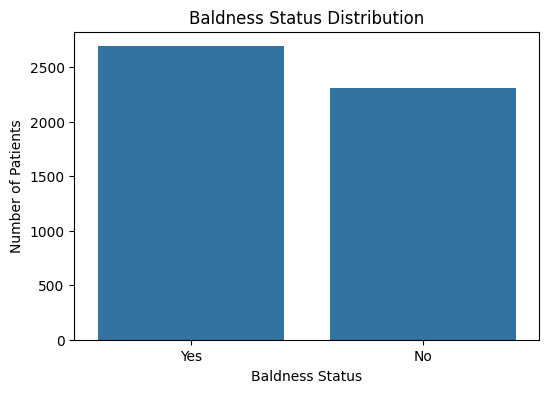

In [9]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="baldness_status")

plt.title("Baldness Status Distribution")
plt.xlabel("Baldness Status")
plt.ylabel("Number of Patients")

plt.show()

In [10]:
df.isnull().sum()

,0
patient_id,0
age,0
gender,0
family_history,0
father_baldness,0
hair_loss_age,0
hair_loss_pattern,3024
norwood_stage,0
hair_density,0
hair_shedding,0


In [11]:
df.groupby("baldness_status")["hair_loss_pattern"].apply(
    lambda x: x.isna().mean() * 100
)

,hair_loss_pattern
baldness_status,
No,90.653397
Yes,34.548159


In [12]:
df.groupby("baldness_status")["treatment"].apply(
    lambda x: x.isna().mean() * 100
)

,treatment
baldness_status,
No,79.056685
Yes,41.911491


In [13]:
# Create a copy for ML
ml_df = df.copy()

# Remove columns that should not be used for prediction
columns_to_drop = [
    "patient_id",
    "gender",
    "hair_loss_pattern",
    "treatment",
    "treatment_id",
    "baldness_risk"
]

ml_df = ml_df.drop(columns=columns_to_drop)

# Check the remaining columns
print("Shape:", ml_df.shape)
print("\nColumns:")
print(ml_df.columns.tolist())

Shape: (5000, 20)

Columns:
['age', 'family_history', 'father_baldness', 'hair_loss_age', 'norwood_stage', 'hair_density', 'hair_shedding', 'scalp_condition', 'stress_level', 'sleep_hours', 'smoking', 'alcohol_consumption', 'diet_type', 'protein_intake', 'exercise_frequency', 'vitamin_d_level', 'iron_level', 'testosterone_level', 'dht_level', 'baldness_status']


In [14]:
ml_df.isnull().sum()

,0
age,0
family_history,0
father_baldness,0
hair_loss_age,0
norwood_stage,0
hair_density,0
hair_shedding,0
scalp_condition,39
stress_level,54
sleep_hours,52


In [15]:
# Make another copy before cleaning
clean_df = ml_df.copy()

# Categorical columns
categorical_cols = [
    "scalp_condition",
    "stress_level",
    "alcohol_consumption"
]

# Numerical columns
numerical_cols = [
    "sleep_hours",
    "vitamin_d_level",
    "iron_level"
]

# Fill categorical missing values
for col in categorical_cols:
    clean_df[col] = clean_df[col].fillna("Unknown")

# Fill numerical missing values with median
for col in numerical_cols:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

# Check missing values again
clean_df.isnull().sum()

,0
age,0
family_history,0
father_baldness,0
hair_loss_age,0
norwood_stage,0
hair_density,0
hair_shedding,0
scalp_condition,0
stress_level,0
sleep_hours,0


In [16]:
print("Rows:", clean_df.shape[0])
print("Columns:", clean_df.shape[1])

Rows: 5000
Columns: 20


In [17]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  5000 non-null   int64  
 1   family_history       5000 non-null   object 
 2   father_baldness      5000 non-null   object 
 3   hair_loss_age        5000 non-null   int64  
 4   norwood_stage        5000 non-null   int64  
 5   hair_density         5000 non-null   int64  
 6   hair_shedding        5000 non-null   object 
 7   scalp_condition      5000 non-null   object 
 8   stress_level         5000 non-null   object 
 9   sleep_hours          5000 non-null   float64
 10  smoking              5000 non-null   object 
 11  alcohol_consumption  5000 non-null   object 
 12  diet_type            5000 non-null   object 
 13  protein_intake       5000 non-null   object 
 14  exercise_frequency   5000 non-null   int64  
 15  vitamin_d_level      5000 non-null   f

In [19]:
categorical_cols = clean_df.select_dtypes(include="object").columns

for col in categorical_cols:
    print("\n", col)
    print(clean_df[col].value_counts())


 family_history
family_history
Yes    2874
No     2126
Name: count, dtype: int64

 father_baldness
father_baldness
Yes    2555
No     2445
Name: count, dtype: int64

 hair_shedding
hair_shedding
Medium    2129
Low       1919
High       952
Name: count, dtype: int64

 scalp_condition
scalp_condition
Normal      2541
Dry          911
Oily         785
Dandruff     724
Unknown       39
Name: count, dtype: int64

 stress_level
stress_level
Medium     2308
High       1424
Low        1214
Unknown      54
Name: count, dtype: int64

 smoking
smoking
No     3884
Yes    1116
Name: count, dtype: int64

 alcohol_consumption
alcohol_consumption
Unknown       2171
Occasional    2074
Regular        755
Name: count, dtype: int64

 diet_type
diet_type
Mixed             1914
Non-vegetarian    1662
Vegetarian        1424
Name: count, dtype: int64

 protein_intake
protein_intake
Medium    2802
High      1116
Low       1082
Name: count, dtype: int64

 baldness_status
baldness_status
Yes    2689
No     2311

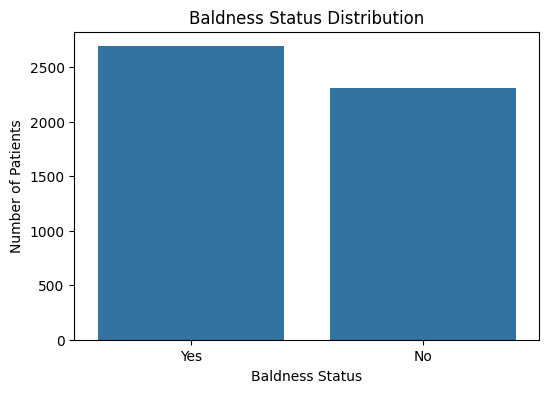

In [20]:
plt.figure(figsize=(6, 4))

sns.countplot(data=clean_df, x="baldness_status")

plt.title("Baldness Status Distribution")
plt.xlabel("Baldness Status")
plt.ylabel("Number of Patients")

plt.show()

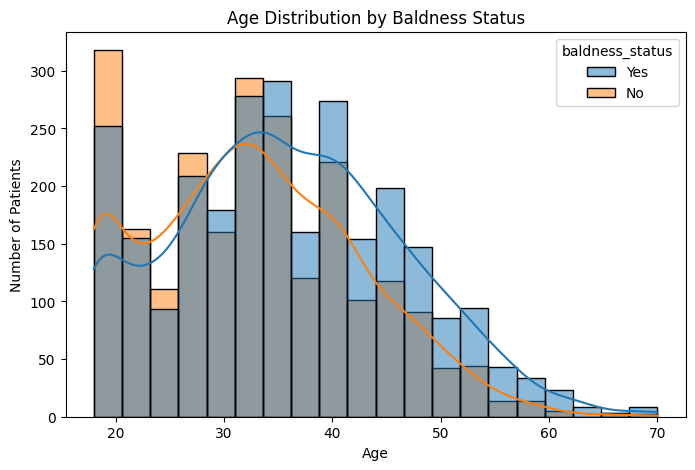

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=clean_df,
    x="age",
    hue="baldness_status",
    bins=20,
    kde=True
)

plt.title("Age Distribution by Baldness Status")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

In [22]:
clean_df.groupby("baldness_status")["age"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
baldness_status,,,,
No,32.703592,32.0,18,70
Yes,35.753068,35.0,18,70


In [23]:
family_baldness = pd.crosstab(
    clean_df["family_history"],
    clean_df["baldness_status"],
    normalize="index"
) * 100

family_baldness

baldness_status,No,Yes
family_history,,
No,66.133584,33.866416
Yes,31.489214,68.510786


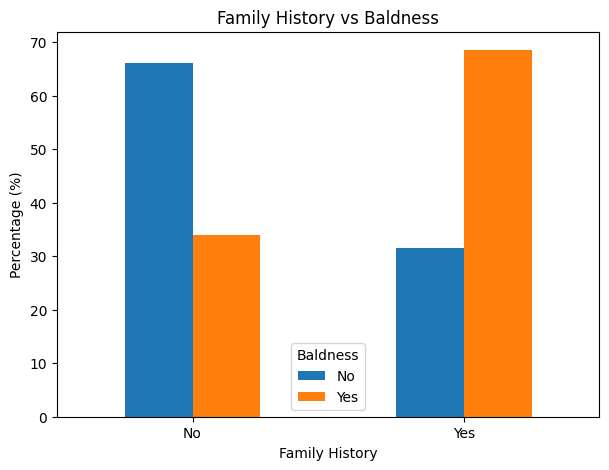

In [24]:
family_baldness.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Family History vs Baldness")
plt.xlabel("Family History")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Baldness")

plt.show()

In [25]:
father_baldness = pd.crosstab(
    clean_df["father_baldness"],
    clean_df["baldness_status"],
    normalize="index"
) * 100

father_baldness

baldness_status,No,Yes
father_baldness,,
No,62.413088,37.586912
Yes,30.724070,69.275930


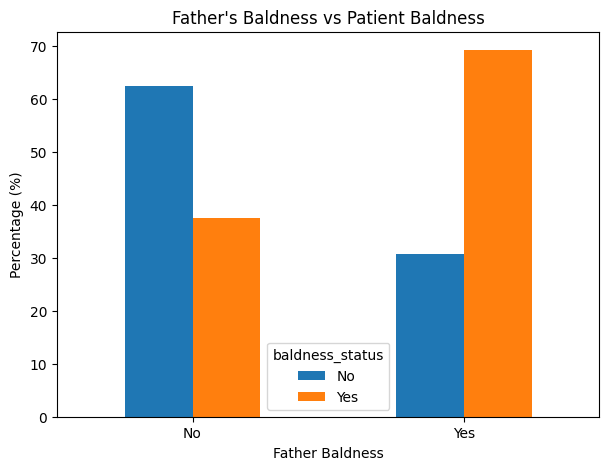

In [26]:
father_baldness.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Father's Baldness vs Patient Baldness")
plt.xlabel("Father Baldness")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.show()

In [27]:
norwood_baldness = pd.crosstab(
    clean_df["norwood_stage"],
    clean_df["baldness_status"],
    normalize="index"
) * 100

norwood_baldness

baldness_status,No,Yes
norwood_stage,,
1,100.000000,0.000000
2,29.218573,70.781427
3,0.000000,100.000000
4,0.000000,100.000000
5,0.000000,100.000000
6,0.000000,100.000000
7,0.000000,100.000000


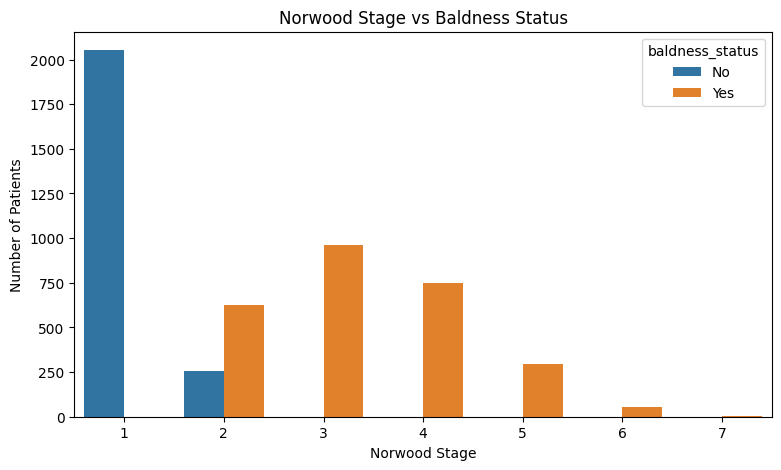

In [28]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=clean_df,
    x="norwood_stage",
    hue="baldness_status"
)

plt.title("Norwood Stage vs Baldness Status")
plt.xlabel("Norwood Stage")
plt.ylabel("Number of Patients")

plt.show()

In [29]:
clean_df.groupby("baldness_status")["hair_density"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
baldness_status,,,,
No,165.089572,165.0,108,190
Yes,131.931573,134.0,47,189


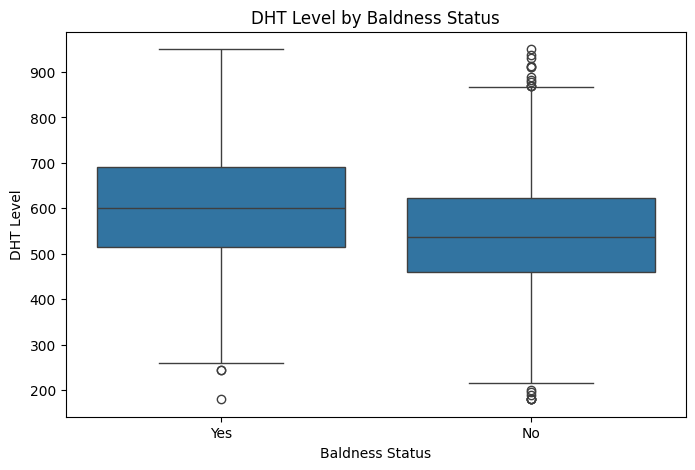

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean_df,
    x="baldness_status",
    y="dht_level"
)

plt.title("DHT Level by Baldness Status")
plt.xlabel("Baldness Status")
plt.ylabel("DHT Level")

plt.show()

In [31]:
clean_df.groupby("baldness_status")["dht_level"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
baldness_status,,,,
No,541.615448,536.7,180.0,950.0
Yes,602.341056,601.6,181.1,950.0


In [32]:
# Hair density statistics
clean_df.groupby("baldness_status")["hair_density"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
baldness_status,,,,
No,165.089572,165.0,108,190
Yes,131.931573,134.0,47,189


In [33]:
# Hair shedding vs baldness
pd.crosstab(
    clean_df["hair_shedding"],
    clean_df["baldness_status"],
    normalize="index"
) * 100

baldness_status,No,Yes
hair_shedding,,
High,17.226891,82.773109
Low,67.378843,32.621157
Medium,40.112729,59.887271


In [34]:
# Stress vs baldness
pd.crosstab(
    clean_df["stress_level"],
    clean_df["baldness_status"],
    normalize="index"
) * 100

baldness_status,No,Yes
stress_level,,
High,43.820225,56.179775
Low,47.858320,52.141680
Medium,47.227036,52.772964
Unknown,29.629630,70.370370


In [35]:
# Sleep vs baldness
clean_df.groupby("baldness_status")["sleep_hours"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
baldness_status,,,,
No,6.816530,7.0,4.0,9.0
Yes,6.762179,7.0,4.0,9.0


In [36]:
# Biological features
clean_df.groupby("baldness_status")[
    ["vitamin_d_level", "iron_level", "testosterone_level", "dht_level"]
].mean()

,vitamin_d_level,iron_level,testosterone_level,dht_level
baldness_status,,,,
No,23.442363,80.897144,525.426266,541.615448
Yes,23.271476,81.160208,520.403384,602.341056


In [37]:
y = clean_df["baldness_status"]

In [38]:
X = clean_df.drop("baldness_status", axis=1)

In [39]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'hair_loss_age', 'norwood_stage', 'hair_density', 'sleep_hours', 'exercise_frequency', 'vitamin_d_level', 'iron_level', 'testosterone_level', 'dht_level']

Categorical Features:
['family_history', 'father_baldness', 'hair_shedding', 'scalp_condition', 'stress_level', 'smoking', 'alcohol_consumption', 'diet_type', 'protein_intake']


In [40]:
y = y.map({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())

baldness_status
1    2689
0    2311
Name: count, dtype: int64


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4000
Testing samples: 1000


In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [44]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000
        ))
    ]
)

In [45]:
logistic_model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppr

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['family_history',
                                                   'father_baldness',
                                                   'hair_shedding',
                                                   'scalp_condition',
                                                   'stress_level', 'smoking',
                                                   'alcohol_consumption',
                                                   'diet_type',
                                                   'protein_intake'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [46]:
y_pred_lr = logistic_model.predict(X_test)

In [47]:
from sklearn.metrics import accuracy_score

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:",
      round(accuracy_lr * 100, 2), "%")

Logistic Regression Accuracy: 94.3 %


In [48]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No Baldness", "Baldness"]
))

              precision    recall  f1-score   support

 No Baldness       0.96      0.91      0.94       462
    Baldness       0.93      0.97      0.95       538

    accuracy                           0.94      1000
   macro avg       0.95      0.94      0.94      1000
weighted avg       0.94      0.94      0.94      1000



In [49]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42,
            max_depth=6
        ))
    ]
)

decision_tree.fit(X_train, y_train)

y_pred_dt = decision_tree.predict(X_test)

In [50]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:",
      round(accuracy_dt * 100, 2), "%")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["No Baldness", "Baldness"]
))

Decision Tree Accuracy: 94.6 %

Classification Report:

              precision    recall  f1-score   support

 No Baldness       0.99      0.89      0.94       462
    Baldness       0.92      0.99      0.95       538

    accuracy                           0.95      1000
   macro avg       0.95      0.94      0.95      1000
weighted avg       0.95      0.95      0.95      1000



In [51]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

In [52]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:",
      round(accuracy_rf * 100, 2), "%")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Baldness", "Baldness"]
))

Random Forest Accuracy: 93.8 %

Classification Report:

              precision    recall  f1-score   support

 No Baldness       0.98      0.88      0.93       462
    Baldness       0.91      0.99      0.94       538

    accuracy                           0.94      1000
   macro avg       0.94      0.93      0.94      1000
weighted avg       0.94      0.94      0.94      1000



In [53]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [54]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (4000, 37)
Testing shape: (1000, 37)


In [55]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train_processed,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [56]:
y_pred_xgb = xgb_model.predict(X_test_processed)

In [57]:
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:",
      round(accuracy_xgb * 100, 2), "%")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["No Baldness", "Baldness"]
))

XGBoost Accuracy: 94.8 %

Classification Report:

              precision    recall  f1-score   support

 No Baldness       0.97      0.92      0.94       462
    Baldness       0.93      0.98      0.95       538

    accuracy                           0.95      1000
   macro avg       0.95      0.95      0.95      1000
weighted avg       0.95      0.95      0.95      1000



In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

In [60]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ]
})

results = results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,XGBoost,0.948,0.9309,0.9758,0.9528
1,Decision Tree,0.946,0.9158,0.9907,0.9518
2,Logistic Regression,0.943,0.9272,0.9703,0.9482
3,Random Forest,0.938,0.9075,0.9851,0.9447


Confusion Matrix:
[[423  39]
 [ 13 525]]


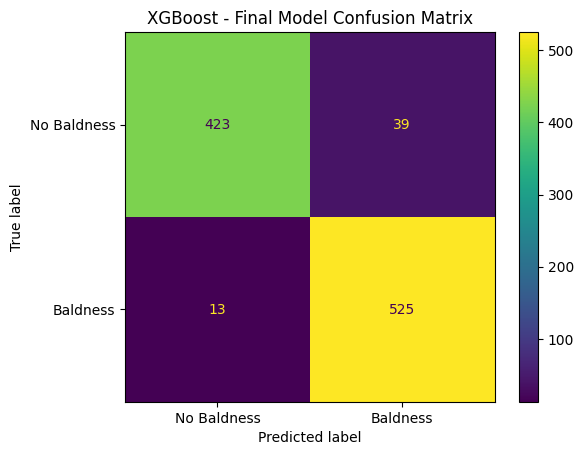

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_xgb)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Baldness", "Baldness"]
)

disp.plot()

plt.title("XGBoost - Final Model Confusion Matrix")
plt.show()

In [62]:
from sklearn.metrics import roc_auc_score

y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost ROC-AUC:",
      round(roc_auc, 4))

XGBoost ROC-AUC: 0.9896


In [63]:
feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(15)

,Feature,Importance
29,remainder__norwood_stage,0.545370
0,categorical__family_history_No,0.067443
30,remainder__hair_density,0.047003
5,categorical__hair_shedding_Low,0.037562
4,categorical__hair_shedding_High,0.024886
2,categorical__father_baldness_No,0.019269
3,categorical__father_baldness_Yes,0.017042
27,remainder__age,0.013658
36,remainder__dht_level,0.011218
23,categorical__diet_type_Vegetarian,0.010652


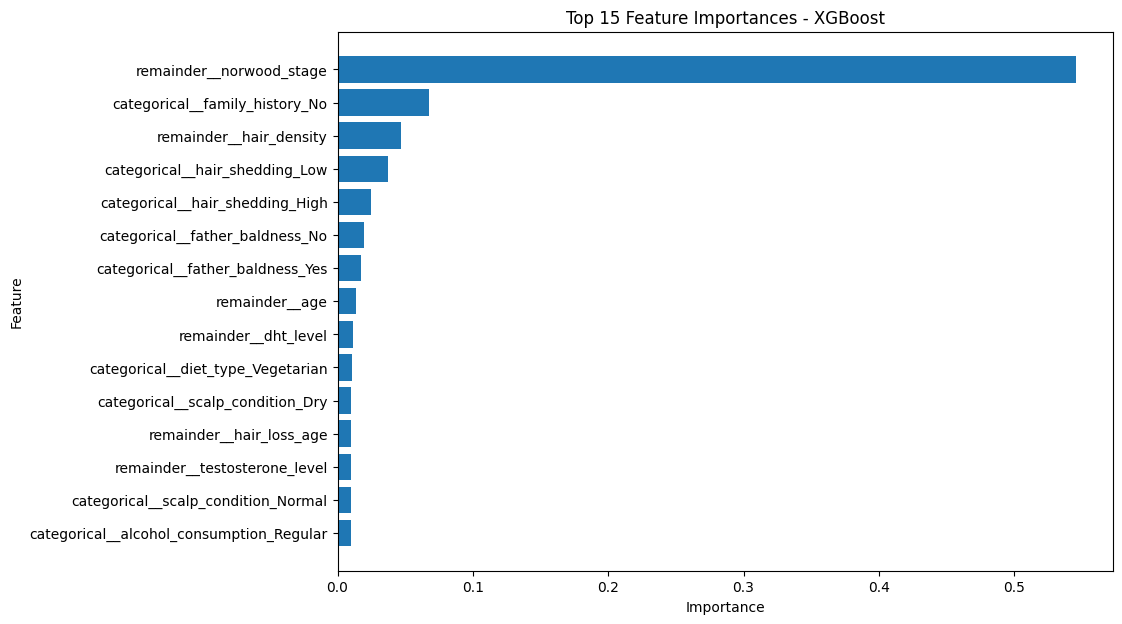

In [64]:
plt.figure(figsize=(10, 7))

top_features = importance.head(15).sort_values(
    "Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importances - XGBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [84]:
def predict_baldness():

    print("====================================")
    print("     MALE BALDNESS PREDICTION")
    print("====================================")

    age = int(input("Enter age: "))

    print("\nFamily History Options: Yes / No")
    family_history = input("Family history of baldness: ").strip().capitalize()

    print("\nFather Baldness Options: Yes / No")
    father_baldness = input(
        "Does your father have baldness: "
    ).strip().capitalize()

    hair_loss_age = int(
        input("\nAt what age did hair loss start: ")
    )

    print("\nNorwood Stage Options: 1 / 2 / 3 / 4 / 5 / 6 / 7")
    norwood_stage = int(
        input("Enter Norwood stage: ")
    )

    hair_density = float(
        input("\nEnter hair density: ")
    )

    print("\nHair Shedding Options: Low / Medium / High")
    hair_shedding = input(
        "Hair shedding level: "
    ).strip().capitalize()

    print("\nScalp Condition Options: Normal / Dry / Oily / Dandruff")
    scalp_condition = input(
        "Scalp condition: "
    ).strip().capitalize()

    print("\nStress Level Options: Low / Medium / High")
    stress_level = input(
        "Stress level: "
    ).strip().capitalize()

    sleep_hours = float(
        input("\nAverage sleep hours per day: ")
    )

    print("\nSmoking Options: Yes / No")
    smoking = input(
        "Do you smoke: "
    ).strip().capitalize()

    print("\nAlcohol Consumption Options: Occasional / Regular / Unknown")
    alcohol_consumption = input(
        "Alcohol consumption: "
    ).strip().capitalize()

    print("\nDiet Type Options: Vegetarian / Non-vegetarian / Mixed")
    diet_type = input(
        "Diet type: "
    ).strip().capitalize()

    print("\nProtein Intake Options: Low / Medium / High")
    protein_intake = input(
        "Protein intake: "
    ).strip().capitalize()

    exercise_frequency = int(
        input("\nExercise frequency per week: ")
    )

    vitamin_d = float(
        input("\nVitamin D level: ")
    )

    iron_level = float(
        input("\nIron level: ")
    )

    testosterone_level = float(
        input("\nTestosterone level: ")
    )

    dht_level = float(
        input("\nDHT level: ")
    )

    # Create DataFrame
    user_data = pd.DataFrame([{
        "age": age,
        "family_history": family_history,
        "father_baldness": father_baldness,
        "hair_loss_age": hair_loss_age,
        "norwood_stage": norwood_stage,
        "hair_density": hair_density,
        "hair_shedding": hair_shedding,
        "scalp_condition": scalp_condition,
        "stress_level": stress_level,
        "sleep_hours": sleep_hours,
        "smoking": smoking,
        "alcohol_consumption": alcohol_consumption,
        "diet_type": diet_type,
        "protein_intake": protein_intake,
        "exercise_frequency": exercise_frequency,
        "vitamin_d_level": vitamin_d,
        "iron_level": iron_level,
        "testosterone_level": testosterone_level,
        "dht_level": dht_level
    }])

    # Apply the SAME preprocessing used during training
    user_data_processed = preprocessor.transform(user_data)

    # XGBoost prediction
    prediction = xgb_model.predict(user_data_processed)[0]

    probability = xgb_model.predict_proba(
        user_data_processed
    )[0][1]

    # Display result
    print("\n====================================")
    print("          PREDICTION RESULT")
    print("====================================")

    if prediction == 1:
        print("Predicted Baldness Status: YES")
    else:
        print("Predicted Baldness Status: NO")

    print(f"Baldness Probability: {probability * 100:.2f}%")

    print("====================================")

In [85]:
predict_baldness()

     MALE BALDNESS PREDICTION
Enter age: 21

Family History Options: Yes / No
Family history of baldness: no

Father Baldness Options: Yes / No
Does your father have baldness: no

At what age did hair loss start: 20

Norwood Stage Options: 1 / 2 / 3 / 4 / 5 / 6 / 7
Enter Norwood stage: 1

Enter hair density: 150

Hair Shedding Options: Low / Medium / High
Hair shedding level: low

Scalp Condition Options: Normal / Dry / Oily / Dandruff
Scalp condition: oily

Stress Level Options: Low / Medium / High
Stress level: medium

Average sleep hours per day: 9

Smoking Options: Yes / No
Do you smoke: no

Alcohol Consumption Options: Occasional / Regular / Unknown
Alcohol consumption: unknown

Diet Type Options: Vegetarian / Non-vegetarian / Mixed
Diet type: mixed

Protein Intake Options: Low / Medium / High
Protein intake: low

Exercise frequency per week: 0

Vitamin D level: 17

Iron level: 90

Testosterone level: 500

DHT level: 600

          PREDICTION RESULT
Predicted Baldness Status: NO
B

In [86]:
import joblib

joblib.dump(xgb_model, "male_baldness_xgboost.pkl")
joblib.dump(preprocessor, "baldness_preprocessor.pkl")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!
